In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression

In [2]:
peng = pd.read_csv('penguins.csv').dropna(
    subset=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']
).reset_index(drop=True)
print(f'n = {len(peng)}')

n = 333


# Part 1

### Question 1

In [3]:
m1 = smf.ols('body_mass_g ~ flipper_length_mm + C(sex) + C(species)', data=peng).fit()
print(m1.params.round(4))
print('R2 =', round(m1.rsquared, 4))

Intercept                 -365.8174
C(sex)[T.male]             530.3811
C(species)[T.Chinstrap]    -87.6345
C(species)[T.Gentoo]       836.2600
flipper_length_mm           20.0249
dtype: float64
R2 = 0.8669


The reference level is female for sex and Adelie for species.

The C(species)[T.Gentoo] coefficient means Gentoo penguins are predicted to weigh about 836 grams more on average than Adelie penguins, holding flipper length and sex constant.

### Question 2

##### Part A

In [4]:
X = pd.get_dummies(peng[['flipper_length_mm', 'sex', 'species']], drop_first=True)
y = peng['body_mass_g']

lr1 = LinearRegression().fit(X, y)
print(round(lr1.intercept_, 4))
print(lr1.coef_.round(4))
print('R2 =', round(lr1.score(X, y), 4))
print(list(X.columns))

-365.8174
[ 20.0249 530.3811 -87.6345 836.26  ]
R2 = 0.8669
['flipper_length_mm', 'sex_male', 'species_Chinstrap', 'species_Gentoo']


##### Part B

You could use bootstrapping to calculate the CIs by repeatedly resampling the data with replacement and refitting the model on each resample. Then build the distribution of the resulting coefficients and use the middle 95 percent of that distribution as the confidence interval for each coefficient.

### Question 3

##### Part A

In [5]:
X_full = pd.get_dummies(peng[['flipper_length_mm', 'sex', 'species']])
print(list(X_full.columns))

['flipper_length_mm', 'sex_female', 'sex_male', 'species_Adelie', 'species_Chinstrap', 'species_Gentoo']


There are two columns for sex and three columns for species.

##### Part B

In [6]:
lr2 = LinearRegression().fit(X_full, y)
print(round(lr2.score(X_full, y), 4))
print(np.abs(lr1.predict(X) - lr2.predict(X_full)).max())

0.8669
7.275957614183426e-12


The R2 is the same at 0.8669 and the predicted values match to floating point precision, with a maximum difference of about 7e-12 grams.

##### Part C

In [7]:
coefs = pd.Series(lr2.coef_, index=X_full.columns)
print(coefs.round(4))
print('sex sum:', abs(round(coefs['sex_female'] + coefs['sex_male'], 4)))
print('species sum:', abs(round(coefs['species_Adelie'] + coefs['species_Chinstrap'] + coefs['species_Gentoo'], 4)))
print('Chinstrap minus Adelie:', round(coefs['species_Chinstrap'] - coefs['species_Adelie'], 4))
print('Gentoo minus Adelie:', round(coefs['species_Gentoo'] - coefs['species_Adelie'], 4))
print('male minus female:', round(coefs['sex_male'] - coefs['sex_female'], 4))

flipper_length_mm     20.0249
sex_female          -265.1905
sex_male             265.1905
species_Adelie      -249.5418
species_Chinstrap   -337.1763
species_Gentoo       586.7182
dtype: float64
sex sum: 0.0
species sum: 0.0
Chinstrap minus Adelie: -87.6345
Gentoo minus Adelie: 836.26
male minus female: 530.3811


The coefficients are not the same as in question 2, except for flipper_length_mm, which stays at 20.0249. Also, the coefficients within each group sum to zero. sex_female plus sex_male is 0 and the three species coefficients add up to 0 as well. However, the differences between the coefficients are exactly the dummy coefficients from question 2. Chinstrap minus Adelie is -87.6345, Gentoo minus Adelie is 836.26, and male minus female is 530.3811.

##### Part D

Without dropping a level, there is no reference group anymore. The predictions and R2 stay the same since the extra columns are just redundant. Because of this, the individual coefficients cannot be read as effects and their values are not unique. The differences between the coefficients are the meaningful quantities, and they match the dummy coefficients from question 2.

### Question 4

##### Part A

In [8]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pre = ColumnTransformer([
    ('flip', 'passthrough', ['flipper_length_mm']),
    ('cat', OneHotEncoder(drop='first'), ['sex', 'species'])
])
pipe = Pipeline([('pre', pre), ('lr', LinearRegression())])
pipe.fit(peng, y)
print(list(pipe.named_steps['pre'].get_feature_names_out()))
print(pipe.named_steps['lr'].coef_.round(4))
print(round(pipe.named_steps['lr'].intercept_, 4))

['flip__flipper_length_mm', 'cat__sex_male', 'cat__species_Chinstrap', 'cat__species_Gentoo']
[ 20.0249 530.3811 -87.6345 836.26  ]
-365.8174


Confirmed, the pipeline produces the same columns and coefficients as question 2. The flip__ and cat__ prefixes are just the ColumnTransformer's naming convention.

##### Part B

In [9]:
new_penguin = pd.DataFrame({'flipper_length_mm': [215], 'sex': ['male'], 'species': ['Gentoo']})
print(pipe.predict(new_penguin))

[5306.18047038]


In [10]:
print(-365.8174 + 20.0249 * 215 + 530.3811 + 836.26)

5306.1772


The model predicts about 5306.18 grams for a male Gentoo penguin with a flipper length of 215 mm. The hand calculation from the question 1 coefficients gives 5306.1772, which matches up to the rounding of the printed coefficients.

# Part 2

### Question 1

In [11]:
X3 = peng[['flipper_length_mm', 'bill_length_mm', 'bill_depth_mm']]
lr3 = LinearRegression().fit(X3, y)
print(pd.Series(lr3.coef_, index=X3.columns).round(4))
print('R2 =', round(lr3.score(X3, y), 4))

flipper_length_mm    50.7621
bill_length_mm        3.2929
bill_depth_mm        17.8364
dtype: float64
R2 = 0.7639


##### Part A

RFE would drop bill_length_mm first, since it has the smallest absolute coefficient at 3.2929.

##### Part B

In [12]:
X3cm = peng[['flipper_length_mm', 'bill_length_mm', 'bill_depth_mm']].copy()
X3cm = X3cm.rename(columns={'bill_length_mm': 'bill_length_cm'})
X3cm['bill_length_cm'] = X3cm['bill_length_cm'] / 10

lr3cm = LinearRegression().fit(X3cm, y)
print(pd.Series(lr3cm.coef_, index=X3cm.columns).round(4))
print('R2 =', round(lr3cm.score(X3cm, y), 4))
print(np.abs(lr3.predict(X3) - lr3cm.predict(X3cm)).max())

flipper_length_mm    50.7621
bill_length_cm       32.9286
bill_depth_mm        17.8364
dtype: float64
R2 = 0.7639
3.637978807091713e-12


The bill_length coefficient increases by a factor of 10, to 32.9286, because its units changed from mm to cm. The flipper_length_mm and bill_depth_mm coefficients are unchanged at 50.7621 and 17.8364, the R2 stays at 0.7639, and the predictions are identical up to floating point precision (maximum difference about 4e-12). RFE would now drop bill_depth_mm first, since 17.8364 is the smallest coefficient in absolute value.

### Question 2

##### Part A

In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

std_pipe = make_pipeline(StandardScaler(), LinearRegression()).fit(X3, y)
print(pd.Series(std_pipe.named_steps['linearregression'].coef_, index=['flipper_length_std', 'bill_length_std', 'bill_depth_std']).round(4))
print('R2 =', round(std_pipe.score(X3, y), 4))

flipper_length_std    710.4010
bill_length_std        17.9805
bill_depth_std         35.0713
dtype: float64
R2 = 0.7639


One unit of a standardized predictor is one standard deviation, so the flipper coefficient of 710.4010 means that a one standard deviation increase in flipper length is associated with about 710 grams more predicted body mass, holding bill length and bill depth constant.

##### Part B

In [14]:
std_pipe_cm = make_pipeline(StandardScaler(), LinearRegression()).fit(X3cm, y)
print(pd.Series(std_pipe_cm.named_steps['linearregression'].coef_, index=['flipper_length_std', 'bill_length_std', 'bill_depth_std']).round(4))
print('R2 =', round(std_pipe_cm.score(X3cm, y), 4))

flipper_length_std    710.4010
bill_length_std        17.9805
bill_depth_std         35.0713
dtype: float64
R2 = 0.7639


Ranked by absolute value, the standardized coefficients are flipper length at 710.4010, bill depth at 35.0713, and bill length at 17.9805, so RFE would drop bill_length first. When bill length is measured in centimeters the coefficients are identical to part a, so the unit conversion does not matter. Standardizing divides each predictor by its standard deviation, so the units of the raw values cancel out.

##### Part C

In [15]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler

minmax_pipe = make_pipeline(MinMaxScaler(), LinearRegression()).fit(X3, y)
print(pd.Series(minmax_pipe.named_steps['linearregression'].coef_, index=['flipper_length_minmax', 'bill_length_minmax', 'bill_depth_minmax']).round(4))

robust_pipe = make_pipeline(RobustScaler(), LinearRegression()).fit(X3, y)
print(pd.Series(robust_pipe.named_steps['linearregression'].coef_, index=['flipper_length_robust', 'bill_length_robust', 'bill_depth_robust']).round(4))

flipper_length_minmax    2994.9658
bill_length_minmax         90.5537
bill_depth_minmax         149.8257
dtype: float64
flipper_length_robust    1167.5290
bill_length_robust         29.9650
bill_depth_robust          55.2928
dtype: float64


All three scalers agree on the ranking, flipper length above bill depth above bill length, so all three would have RFE drop bill_length first. The magnitudes differ and are not directly comparable across scalers, for example flipper length has coefficients of 710.4010 under StandardScaler, 2994.9658 under MinMaxScaler, and 1167.5290 under RobustScaler. The unit each scaler uses is different, StandardScaler uses one standard deviation, MinMaxScaler uses the full range between the minimum and the maximum, and RobustScaler uses the interquartile range.

##### Part D

In [16]:
X3c = X3 - X3.mean()
lr3c = LinearRegression().fit(X3c, y)
print(pd.Series(lr3c.coef_, index=X3c.columns).round(4))
print(round(lr3c.intercept_, 4))
print('R2 =', round(lr3c.score(X3c, y), 4))
print('original intercept:', round(lr3.intercept_, 4))

flipper_length_mm    50.7621
bill_length_mm        3.2929
bill_depth_mm        17.8364
dtype: float64
4207.0571
R2 = 0.7639
original intercept: -6445.476


Relative to the original-units model, centering changes only the intercept, from -6445.476 to 4207.0571. The coefficients and the R2 are unchanged at 50.7621, 3.2929, 17.8364, and 0.7639. The new intercept is the predicted body mass when all the predictors are at their average values.

### Question 3

In [17]:
orig = lr3
cm = lr3cm
cent = lr3c
std = std_pipe.named_steps['linearregression']
minmax = minmax_pipe.named_steps['linearregression']

table = pd.DataFrame({
    'coefficients': [orig.coef_.round(4), cm.coef_.round(4), cent.coef_.round(4), std.coef_.round(4), minmax.coef_.round(4)],
    'intercept': [round(orig.intercept_, 4), round(cm.intercept_, 4), round(cent.intercept_, 4), round(std.intercept_, 4), round(minmax.intercept_, 4)],
    'R2': [round(orig.score(X3, y), 4), round(cm.score(X3cm, y), 4), round(cent.score(X3c, y), 4), round(std_pipe.score(X3, y), 4), round(minmax_pipe.score(X3, y), 4)],
}, index=['original units', 'bill length in cm', 'centered predictors', 'StandardScaler', 'MinMaxScaler'])
table

,coefficients,intercept,R2
original units,"[50.7621, 3.2929, 17.8364]",-6445.4760,0.7639
bill length in cm,"[50.7621, 32.9286, 17.8364]",-6445.4760,0.7639
centered predictors,"[50.7621, 3.2929, 17.8364]",4207.0571,0.7639
StandardScaler,"[710.401, 17.9805, 35.0713]",4207.0571,0.7639
MinMaxScaler,"[2994.9658, 90.5537, 149.8257]",2624.9682,0.7639


##### Part A

In [18]:
fits = [cm, cent, std, minmax]
whole = [lr3cm, lr3c, std_pipe, minmax_pipe]
Xin = [X3cm, X3c, X3, X3]

coefs_changed = [False]
intercept_changed = [False]
r2_changed = [False]
preds_changed = [False]

for i in range(len(fits)):
    coefs_changed.append(not np.allclose(fits[i].coef_, orig.coef_))
    intercept_changed.append(not np.allclose(fits[i].intercept_, orig.intercept_))
    r2_changed.append(not np.allclose(whole[i].score(Xin[i], y), orig.score(X3, y)))
    preds_changed.append(not np.allclose(whole[i].predict(Xin[i]), orig.predict(X3)))

table['coefs_changed'] = coefs_changed
table['intercept_changed'] = intercept_changed
table['R2_changed'] = r2_changed
table['preds_changed'] = preds_changed
table

,coefficients,intercept,R2,coefs_changed,intercept_changed,R2_changed,preds_changed
original units,"[50.7621, 3.2929, 17.8364]",-6445.4760,0.7639,False,False,False,False
bill length in cm,"[50.7621, 32.9286, 17.8364]",-6445.4760,0.7639,True,False,False,False
centered predictors,"[50.7621, 3.2929, 17.8364]",4207.0571,0.7639,False,True,False,False
StandardScaler,"[710.401, 17.9805, 35.0713]",4207.0571,0.7639,True,True,False,False
MinMaxScaler,"[2994.9658, 90.5537, 149.8257]",2624.9682,0.7639,True,True,False,False


##### Part B

In [19]:
z = pd.DataFrame(StandardScaler().fit_transform(X3), columns=X3.columns)
z['body_mass_g'] = y

m_orig = smf.ols('body_mass_g ~ flipper_length_mm + bill_length_mm + bill_depth_mm', data=peng).fit()
m_std = smf.ols('body_mass_g ~ flipper_length_mm + bill_length_mm + bill_depth_mm', data=z).fit()

print('T-STATS, original units:')
print(m_orig.tvalues.round(2))
print()
print('T-STATS, standardized:')
print(m_std.tvalues.round(2))
print()
print('P-VALUES, original units:')
print(m_orig.pvalues)
print()
print('P-VALUES, standardized:')
print(m_std.pvalues)

T-STATS, original units:
Intercept           -11.39
flipper_length_mm    20.33
bill_length_mm        0.61
bill_depth_mm         1.29
dtype: float64

T-STATS, standardized:
Intercept            195.35
flipper_length_mm     20.33
bill_length_mm         0.61
bill_depth_mm          1.29
dtype: float64

P-VALUES, original units:
Intercept            1.526094e-25
flipper_length_mm    4.446424e-60
bill_length_mm       5.398636e-01
bill_depth_mm        1.979335e-01
dtype: float64

P-VALUES, standardized:
Intercept            0.000000e+00
flipper_length_mm    4.446424e-60
bill_length_mm       5.398636e-01
bill_depth_mm        1.979335e-01
dtype: float64


For the slopes, the t-statistics and p-values are identical in the two fits. Flipper length has t 20.33 and p 4.446424e-60, bill length has t 0.61 and p 0.5398636, and bill depth has t 1.29 and p 0.1979335 in both. Only the intercept's t-statistic changes, from -11.39 to 195.35. This shows that linear scaling changes the size of the coefficients but not the fit itself, so the significance of the slopes and the predicted values are both unaffected.

##### Part C

In [20]:
X3log = np.log(X3)
lr3log = LinearRegression().fit(X3log, y)

table.loc['log predictors'] = [lr3log.coef_.round(4), round(lr3log.intercept_, 4), round(lr3log.score(X3log, y), 4),
                               not np.allclose(lr3log.coef_, orig.coef_),
                               not np.allclose(lr3log.intercept_, orig.intercept_),
                               not np.allclose(lr3log.score(X3log, y), orig.score(X3, y)),
                               not np.allclose(lr3log.predict(X3log), orig.predict(X3))]

table

,coefficients,intercept,R2,coefs_changed,intercept_changed,R2_changed,preds_changed
original units,"[50.7621, 3.2929, 17.8364]",-6445.4760,0.7639,False,False,False,False
bill length in cm,"[50.7621, 32.9286, 17.8364]",-6445.4760,0.7639,True,False,False,False
centered predictors,"[50.7621, 3.2929, 17.8364]",4207.0571,0.7639,False,True,False,False
StandardScaler,"[710.401, 17.9805, 35.0713]",4207.0571,0.7639,True,True,False,False
MinMaxScaler,"[2994.9658, 90.5537, 149.8257]",2624.9682,0.7639,True,True,False,False
log predictors,"[10067.8569, 220.5674, 221.5496]",-50621.3390,0.7554,True,True,True,True


For the linear transformations the R2 and the predictions stayed the same in every case, while only the coefficient sizes and the intercept changed. With the log predictors everything changes, including the predictions, and the R2 drops slightly from 0.7639 to 0.7554. This is because the log is a nonlinear transformation that changes the shape of the data rather than just its units.

### Question 4

##### Part A

Text(0, 0.5, 'number of days')

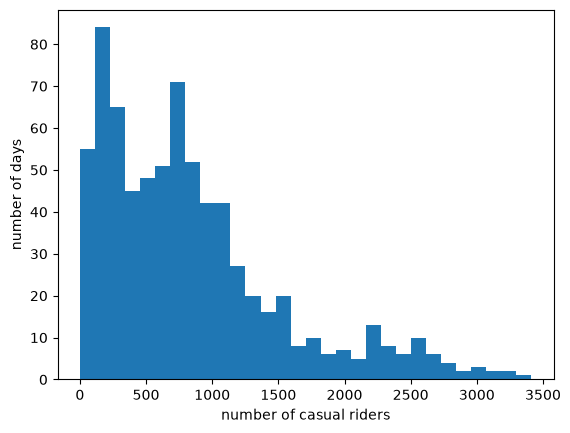

In [21]:
bike = pd.read_csv('bike-sharing-daily.csv')
bike['casual'].plot.hist(bins=30)
plt.xlabel('number of casual riders')
plt.ylabel('number of days')

The histogram is right-skewed. It is highest at low numbers of casual riders and drops as the number of casual riders increases, with a long tail of a few days above 3000 riders.

##### Part B

0.6291


<Axes: xlabel='fitted', ylabel='residuals'>

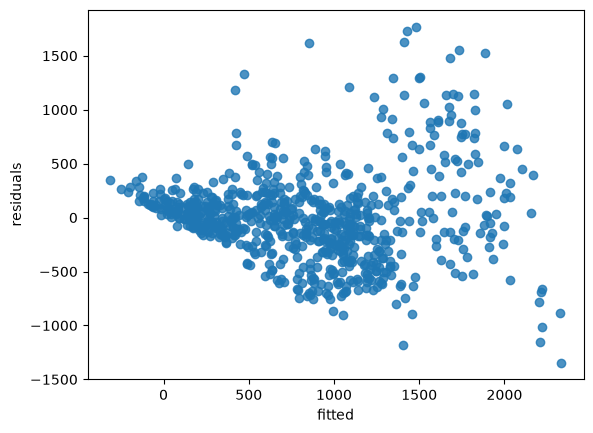

In [22]:
Xb = bike[['temp', 'hum', 'windspeed', 'workingday']]
y_b = bike['casual']
lr_b = LinearRegression().fit(Xb, y_b)
print(round(lr_b.score(Xb, y_b), 4))

bike['fitted'] = lr_b.predict(Xb)
bike['residuals'] = y_b - bike['fitted']

sns.regplot(data=bike, x='fitted', y='residuals', fit_reg=False)

The residuals are not evenly scattered around zero. The cloud is tight at low fitted values and fans out widely as the fitted values increase, and the densest part of the cloud drifts downward as the fitted values increase. The errors get much larger for the larger predicted counts.

##### Part C

In [23]:
print('zeros in casual:', (bike['casual'] == 0).sum())

y_bl = np.log(bike['casual'])
lr_bl = LinearRegression().fit(Xb, y_bl)
print(round(lr_bl.score(Xb, y_bl), 4))

zeros in casual: 0
0.6602


Text(0, 0.5, 'number of days')

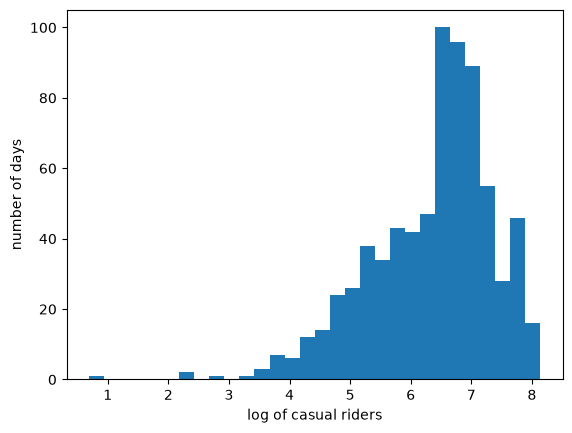

In [24]:
y_bl.plot.hist(bins=30)
plt.xlabel('log of casual riders')
plt.ylabel('number of days')

<Axes: xlabel='fitted_log', ylabel='residuals_log'>

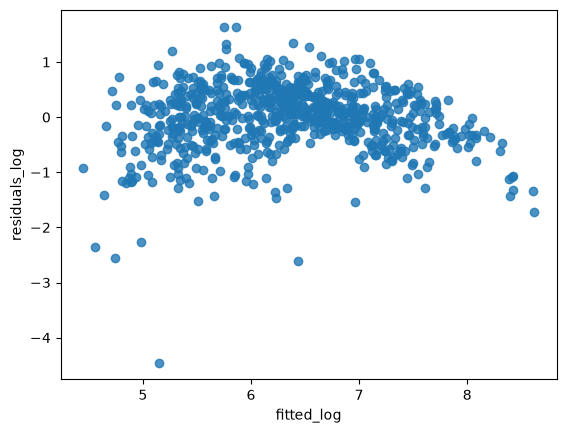

In [25]:
bike['fitted_log'] = lr_bl.predict(Xb)
bike['residuals_log'] = y_bl - bike['fitted_log']

sns.regplot(data=bike, x='fitted_log', y='residuals_log', fit_reg=False)

Casual has no zeros, so np.log was used for the transformation. The histogram is now much closer to symmetric, centered around 6.5 on the log scale, and the long right tail from the raw counts is gone. The residual plot no longer fans out, the spread is roughly constant across the fitted values, though a few large negative residuals remain for very low counts. The R2 of the log model is 0.6602, compared with 0.6291 for the raw-scale model.

##### Part D

Yes, the histogram had a long right tail and the readings say a log suits right-skewed data, so the transformation made the histogram closer to a normal distribution. It had the expected impact, the long right tail is gone and the residuals are now spread much more evenly around zero. It was similar to what we did with Kepler's Law, but there the transformation was applied to both variables to straighten a power-law relationship, while here it was applied only to the response to fix its skew and variance.

# Part 3

Part 3 was submitted by Carlos Orellana, computing ID qrk9cs, for my group. It is included in his Lab submission.

# AI acknowledgment

I used an AI assistant to help write code for this lab. I checked the outputs myself against the data and the class materials to make sure the code worked correctly. I also used AI to help with spelling and grammar in my written answers. All questions were answered in my own words.